# 01. Diabetes Complications
$1^{st}$ **Student.**
- Name: Matteo
- Lastname: Canghiari
- Email: macan26@student.sdu.dk

$2^{nd}$ **Goal.**

Predict whether a patient with diabetes will have a complication three years from now, using only what we know today.

$3^{rd}$ **Software versions and technical stuff.**
- Python 3.12.3.
- Packages installed reported in ../requirements.txt.
- Whole project available on [Canghiari04/Machine-Learning-with-Administrative-Health-Data/Assignment_1](https://github.com/Canghiari04/Machine-Learning-with-Administrative-Health-Data/tree/main/Assignment_1) GitHub repository.
  
$4^{th}$ **Acronyms meaning.**
- `lr` $\rightarrow$ Logistic Regression.
- `rf` $\rightarrow$ Random Forest.
- `xgb` $\rightarrow$ XGBoost.

In [1]:
N_SPLITS = 5
RANDOM_STATE = 42
MODELS = ["lr", "rf", "xgb"]

TARGET_OUTCOMES = ["tissue_infection", "nephropathy"]
OUTCOMES = ["tissue_infection", "retinopathy", "cardiovascular", "nephropathy"]

FUTURE_TARGET_OUTCOMES = ["future_tissue_infection", "future_nephropathy"]
FUTURE_OUTCOMES = ["future_tissue_infection", "future_retinopathy", "future_cardiovascular", "future_nephropathy"]

## Part 0: utility functions
### Task 0: Load packages and code utility functions
$1^{st}$ **Briefly explain what each package does.**

**Core Libraries**
- `numpy` $\rightarrow$ Fundamental library for Python numerical computing.
- `pandas` $\rightarrow$ Python package used for data manipulation and analysis.

**Machine Learning**
- `sklearn` $\rightarrow$ Python library designed for machine learning and data modeling.
- `xgboost` $\rightarrow$ Open-source eXtreme Gradient Boosting library for machine learning.

**Visualization**
- `tabulate` $\rightarrow$ Pretty-print tabular data in Python.
- `seaborn` $\rightarrow$ Library that uses Matplotlib to plot graphs.
- `IPython.display` $\rightarrow$ Library for display tools in Python. 
- `matplotlib.pylot` $\rightarrow$ Low level library for controlling figures, axes, and rendering.

**Stats**
- `scipy.stats` $\rightarrow$ Statistical tests and distributions.
- `fairlearn` $\rightarrow$ Python package to assess system's fairness.

In [2]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from tabulate import tabulate
from sklearn.base import clone
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from scipy.stats import chi2_contingency
from IPython.display import display, HTML
from pandas.api.types import CategoricalDtype
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier    
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, average_precision_score
from fairlearn.metrics import true_positive_rate, false_positive_rate, selection_rate, MetricFrame
from sklearn.model_selection import cross_val_predict, StratifiedGroupKFold, GridSearchCV, RandomizedSearchCV

$2^{nd}$ **Provide all the utility functions.**

This section contains all the utility functions and methods used in the current Python notebook.

In [3]:
warnings.filterwarnings("ignore")

In [4]:
def check_outcomes(df: pd.DataFrame):
    """
        It computes prevalence and temporal-behavior statistics on the dataset. \n
        **Parameters**:
        - **df**: the source dataframe.
    """

    table = []
    headers = ["outcome", "share_months", "share_people", "n_patients", "p(outcome|0)", "p(outcome|1)"]

    grouped_by_pnr = df.groupby("pnr")
    n_people = grouped_by_pnr.ngroups

    for outcome in OUTCOMES:
        # Percentage of months where the outcome event occured
        share_months = round(df[outcome].mean() * 100, 2)

        # Percentage of patients having the outcome at least in a month
        share_people = round((grouped_by_pnr[outcome].max().sum() / n_people) * 100, 2)

        months_per_person = grouped_by_pnr[outcome].sum()
        affected = months_per_person[months_per_person > 0]

        # Values of the previous about the same patients
        previous_months = grouped_by_pnr[outcome].shift(1)
        valid = previous_months.notna()

        tb = pd.crosstab(previous_months[valid], df[outcome][valid], normalize = "index") 

        # Conditional probability of a new outcome starts in the current month
        p_new_event = round((tb.loc[0, 1] * 100), 2)

        # Conditional probability of the outcome persisting in the current month
        p_event_persist = round((tb.loc[1, 1] * 100), 2)

        table.append([outcome, share_months, share_people, len(affected), p_new_event, p_event_persist])
    
    print(tabulate(tabular_data = table, headers = headers))

In [5]:
def infer_feature_types(exclude: list[str], df: pd.DataFrame) -> dict[str, list[str]]:
    """
        It classifies each feature in a dtype. Dtypes detected: [date, categorical, count, income, binary, continuous]. \n
        **Parameters**:
        - **exclude**: list of features to exclude from the detection.
        - **df**: the source dataframe.
    """

    df = df.copy().drop(columns = exclude)
    features = {"date": [], "categorical": [], "count": [], "income": [], "binary": [], "continuous": []}
    for column in df.columns:
        feature = df[column]

        feature_dropped_na = feature.dropna()
        unique_values = feature_dropped_na.nunique()

        dtype = feature.dtype
        name = feature.name

        is_numeric = pd.api.types.is_numeric_dtype(dtype)
        is_date_time = pd.api.types.is_datetime64_any_dtype(dtype)

        is_categorical = isinstance(dtype, CategoricalDtype)

        if is_date_time:
            features["date"].append(name)
        
        if is_categorical:
            features["categorical"].append(name)

        if is_numeric and "count" in name:
            features["count"].append(name)
        elif is_numeric and "income" in name:
            features["income"].append(name)
        elif is_numeric and unique_values == 2:
            features["binary"].append(name)
        elif is_numeric and unique_values <= TRADE_OFF:
            features["categorical"].append(name)
        elif is_numeric:
            features["continuous"].append(name)

    return features

In [6]:
def analyze_count(feature: str, outcome: str, df: pd.DataFrame) -> dict:
    """
        It computes univariate association statistics between a single count feature and an outcome. \n
        **Parameters**:
        - **feature**: count feature.
        - **outcome**: name of the target.
        - **df**: the source dataframe.
    """
    
    sub_df = df[[feature, outcome]].dropna()

    try:
        auc = roc_auc_score(sub_df[outcome], sub_df[feature])
        auc = max(auc, 1 - auc)         
    except ValueError:
        auc = np.nan

    return {"feature": feature, "type": "count", "univariate_auc": auc}

In [7]:
def analyze_binary(feature: str, outcome: str, df: pd.DataFrame) -> dict:
    """
        It computes univariate association statistics between a single binary feature and an outcome. \n
        **Parameters**:
        - **feature**: binary feature.
        - **outcome**: name of the target.
        - **df**: the source dataframe.
    """

    sub_df = df[[feature, outcome]].dropna()

    cross_table = pd.crosstab(sub_df[feature], sub_df[outcome])

    p1 = cross_table.loc[1, 1] / cross_table.loc[1].sum()
    p0 = cross_table.loc[0, 1] / cross_table.loc[0].sum()
    risk_ratio = (p1 / p0)

    n = cross_table.values.sum()
    chi2, _, _, _ = chi2_contingency(cross_table)
    cramers_v = np.sqrt(chi2 / (n * (min(cross_table.shape) - 1)))
    
    return {"feature": feature, "type": "binary", "risk_ratio": risk_ratio, "cramers_v": cramers_v}

In [8]:
def analyze_continuous(feature: str, outcome: str, df: pd.DataFrame) -> dict:
    """
        It computes univariate association statistics between a single continuous feature and an outcome. \n
        **Parameters**:
        - **feature**: continuous feature.
        - **outcome**: name of the target.
        - **df**: the source dataframe.
    """

    sub_df = df[[feature, outcome]].dropna()

    auc = roc_auc_score(sub_df[outcome], sub_df[feature])
    auc = max(auc, 1 - auc)
    
    return {"feature": feature, "type": "continuous", "univariate_auc": auc}

In [9]:
def analyze_categorical(feature: str, outcome: str, df: pd.DataFrame) -> dict:
    """
        It computes univariate association statistics between a single categorical feature and an outcome. \n
        **Parameters**:
        - **feature**: categorical feature.
        - **outcome**: name of the target.
        - **df**: the source dataframe.
    """
    
    sub_df = df[[feature, outcome]].dropna()

    cross_table = pd.crosstab(sub_df[feature], sub_df[outcome])

    n = cross_table.values.sum()
    chi2, _, _, _ = chi2_contingency(cross_table)
    cramers_v = np.sqrt(chi2 / (n * (min(cross_table.shape) - 1)))

    return {"feature": feature, "type": "categorical", "cramers_v": cramers_v}

In [10]:
ANALYZERS = {
    "count": analyze_count, 
    "binary": analyze_binary,
    "income": analyze_continuous,
    "continuous": analyze_continuous,
    "categorical": analyze_categorical
}

def explore_outcomes(dict_features: dict, df: pd.DataFrame) -> dict:
    """
        It runs univariate analyzers for every feature and outcome, and it returns one DataFrame per outcome containing all the useful information. \n
        **Parameters**:
        - **dict_features**: dictionary containing deduced features.
        - **df**: the source dataframe.
    """

    dataframes = {}
    for outcome in OUTCOMES:
        rows = []
        for dtype, features in dict_features.items():
            feature_analyzer = ANALYZERS.get(dtype)
            if feature_analyzer is None:
                continue

            for feature in features:
                row = feature_analyzer(feature = feature, outcome = outcome, df = df)
                if row is not None:
                    rows.append(row)

        dataframes[outcome] = pd.DataFrame(rows).reset_index(drop = True)

    return dataframes

In [11]:
def provide_html(dict: dict[str, pd.DataFrame]) -> str:
    """
        It returns the horizontal visualization of a dictionary of dataframes. \n
        **Parameters**:
        - **dict**: dictionary containing pairs (key, value) --> (string, dataframe).
    """

    html = "<div style = 'display:flex; flex-direction:row; gap:20px; overflow-x:auto; align-items:flex-start;'>"
    for key, value in dict.items():
        html += f"<div><p style = 'font-weight: bold;'>{key}</p><div style = 'flex:0 0 auto;'>{value.to_html()}</div></div>"
    html += "</div>"

    return html

In [12]:
def plot_continuous(features: list, df: pd.DataFrame):
    """
        It creates a 2x2 grids plots showing continuous features. \n
        **Parameters**:
        - **features**: continuous features.
        - **df**: the source dataframe.
    """ 
    
    df_sub = df[features].copy()

    df_sample = df_sub.sample(frac = 0.1, random_state = RANDOM_STATE)
    
    _, axes = plt.subplots(nrows = 2, ncols = 2, figsize = (10, 10))
    axes = axes.ravel()

    for i, feature in zip(range(0, len(axes)), features):
        ax = axes[i]

        sns.histplot(data = df_sample, x = feature, kde = True, ax = ax)

        ax.grid()

    plt.tight_layout()
    plt.show()

In [13]:
PLOTTERS = {
    "continuous": plot_continuous
}

def plot_outcome(dict_features: dict, df: pd.DataFrame):
    """
        It plots features grouped by type against an outcome. \n
        **Parameters**:
        - **outcome**: name of the target.
        - **dict_features**: dictionary containing deduced features.
        - **df**: the source dataframe.
    """

    for dtype, features in dict_features.items():
        feature_plotter = PLOTTERS.get(dtype)
        if feature_plotter is None: 
            continue
            
        feature_plotter(features = features, df = df)

In [14]:
def select_features(risk_ratio_threshold: float = 1.05, cramer_threshold: float = 0.10, auc_count: float = 0.55, auc_continuous: float = 0.60, dict_dataframes: dict = None) -> dict[str, list]:
    """
        It selects and returns a dictionary of all the features having a strong correlation with the target outcomes. \n
        **Parameters**:
        - **risk_ratio_threshold**: minimum risk ratio for binary features.
        - **cramer_threshold**: minimum Cramér's V for categorical features.
        - **auc_count**: minimum univariate AUC for count features.
        - **auc_continuous**: minimum univariate AUC for continuous features.
        - **dict_dataframes**: the source dataframe.s ordered by outcomes.
    """

    selected_features = {}
    for outcome in TARGET_OUTCOMES:
        df = dict_dataframes.get(outcome)

        count_features = (df["type"] == "count") & (df["univariate_auc"] >= auc_count)
        categorical_features = (df["type"] == "categorical") & (df["cramers_v"] >= cramer_threshold)
        continuous_features = (df["type"] == "continuous") & (df["univariate_auc"] >= auc_continuous)
        binary_features = (df["type"] == "binary") & (np.maximum(df["risk_ratio"], 1 / df["risk_ratio"]) >= risk_ratio_threshold)

        selected_features[outcome] = df.loc[count_features].feature.tolist() + df.loc[binary_features].feature.tolist() + df.loc[categorical_features].feature.tolist() + df.loc[continuous_features].feature.tolist()

    return selected_features

In [15]:
def computing_common_percentages(df: pd.DataFrame) -> str:
    """
        Function used to compute percentages of the outcomes at row-level and patient-level. \n
        **Parameters**:
        - **df**: the source dataframe.
    """

    # Number of patients
    n_patients = df["pnr"].nunique()

    table = []
    headers = ["outcome", "rows", "positives", "row-level", "patient-level"]
    
    # 1. Compute: `How common is the complication between rows?`
    # 2. Compute: `How many patients had at least one complication in the last 2 years?`

    for future_outcome in FUTURE_TARGET_OUTCOMES:
        # 1.
        n_valid = int(df[future_outcome].notna().sum())
        n_pos = int(df[future_outcome].sum())
        prev_row = round(n_pos / n_valid * 100, 2)

        # 2.
        counter = df[df[future_outcome] == 1]["pnr"].nunique()
        percentage = round((counter / n_patients) * 100, 2)

        table.append([f"{future_outcome}", n_valid, n_pos, f"{prev_row}%", f"{percentage}%"])

    return tabulate(tabular_data = table, headers = headers, numalign = "left", stralign = "left")

In [16]:
def window(df, col, w = 4):
    """
        Utility function used for rolling purposes. \n
        **Parameters**:
        - **df**: the source dataframe.
        - **col**: specific column to roll.    
    """

    return pd.concat([df.groupby("pnr")[col].shift(-k) for k in range(w)], axis = 1)

In [17]:
def rolling_dataset(list_features: list, exclude: list, dict_features: dict, df: pd.DataFrame) -> pd.DataFrame:
    """
        It returns the dataframe with the selected features already rolled. \n
        **Parameters**:
        - **list_features**: list of features selected.
        - **exclude**: features not rolled.
        - **df**: the source dataframe.
    """

    df_result = df.copy()

    _ = [feature for feature in list_features if feature not in exclude]

    for feature in _:
        dtype = next((key for key, names in dict_features.items() if feature in names), None)
        if dtype is None:
            continue

        rolling_fuc = MAPPING_ROLLING.get(dtype)
        df_result[f"{feature}_rolling"] = rolling_fuc(df_result, feature) 

    return df_result

In [18]:
def examine_continuous_features(list_features: list, df: pd.DataFrame):
    """
        It examines whether continuous features have a linear or non-linear relation with the target outcomes. \n
        **Parameters**:
        - **outcome**: name of the target.
        - **list_features**: continuous features.
        - **df**: the source dataframe. 
    """
    
    _, axes = plt.subplots(nrows = len(list_features), ncols = 2, figsize = (12.5, 12.5))
    for future_outcome in FUTURE_TARGET_OUTCOMES:
        for i, feature in enumerate(list_features):
            sub_df = df[[feature, future_outcome]].copy().dropna()

            # Convert the outcome to float so `.mean()` function works
            sub_df[future_outcome] = sub_df[future_outcome].astype(float)

            # Bin the feature into 10 groups of same cardinality
            sub_df["decile"] = pd.qcut(sub_df[feature], 10, labels = False, duplicates = "drop")

            # For each decile:
            # - `x` mean value of the feature in that decile
            # - `rate` proportion of positive outcomes in that decile
            binned = sub_df.groupby("decile").agg(x = (feature, "mean"), rate = (future_outcome, "mean")).reset_index()
            binned["log_odds"] = np.log(binned["rate"] / (1 - binned["rate"]))
            binned["feature"] = feature

            # Plot event rate 
            axes[i, 0].plot(binned["x"], binned["rate"], marker = "o", label = future_outcome)
            axes[i, 0].set_title(f"{feature}: event rate by decile")
            axes[i, 0].set_xlabel(feature)
            axes[i, 0].set_ylabel("rate")
            axes[i, 0].legend()
            axes[i, 0].grid()

            # Plot log-odds
            axes[i, 1].plot(binned["x"], binned["log_odds"], marker = "o", label = future_outcome)
            axes[i, 1].set_title(f"{feature}: log-odds by decile")
            axes[i, 1].set_ylabel("log-odds")
            axes[i, 1].set_xlabel(feature)
            axes[i, 1].legend()
            axes[i, 1].grid()
    
    plt.tight_layout()
    plt.show()

In [19]:
def split_continuous_in_groups(df: pd.DataFrame) -> pd.DataFrame:
    """
        Utility function used for binning continuous features. \n
        **Parameters**:
        - **df**: the source dataframe.
    """
    df_copy = df.copy()

    # Binning non-linear continuous features 
    df_copy["egfr_binned"] = pd.cut(
        df_copy["egfr_rolling"],
        bins = [-np.inf, 30, 60, 90, np.inf],
        labels = ["<30", "30-59", "60-89", ">=90"],
        right = False
    )

    df_copy["hba1c_binned"] = pd.cut(
        df_copy["hba1c_rolling"],
        bins = [-np.inf, 7, 8, np.inf],
        labels = ["<7", "7-8", ">=8"],
        right = False
    )

    # Log transformation of the right-skewed feature 
    df_copy["albumin_log"] = np.log1p(df_copy["albumin_rolling"])

    return df_copy

In [20]:
def detect_categorical_features(df: pd.DataFrame) -> list[str]:
    """
        It detects from the dataframe given all the categorical features. \n
        **Parameters**:
        - **df**: the source dataframe.
    """

    df_copy = df.copy()
    categorical_features = []
    for column in df_copy.columns:
        if isinstance(df[column].dtype, (str, CategoricalDtype)):
            categorical_features.append(column)

    return categorical_features

In [21]:
def transform_categorical_in_binary(list_features: list, df: pd.DataFrame) -> pd.DataFrame:
    """
        It converts categorical features into binary features, i.e. from strings to numbers. \n
        **Parameters**: 
        - **features**: list of categorical features.
        - **df**: the source dataframe.
    """
    
    _ = pd.DataFrame()
    for feature in list_features:
        dummies = pd.get_dummies(df[feature]).astype("int")
        _ = pd.concat([_, dummies], axis = 1)

    return pd.concat([df, _], axis = 1)

In [22]:
def get_sample(sample_ratio: float, df: pd.DataFrame) -> pd.DataFrame:
    """
        It provides a portion of the training dataframe based on a specific `simple_ratio`. \n
        **Parameters**:
        - **sample_ratio**: ratio used to get the sample.
        - **df**: the source dataframe.
    """

    unique_pnrs = df["pnr"].unique()
    sampled_pnrs = pd.Series(unique_pnrs).sample(frac = sample_ratio, random_state = RANDOM_STATE).values

    return df[df["pnr"].isin(sampled_pnrs)]

In [23]:
def get_xy(outcome: str, model: str, df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    """
        It returns a tuple composed by all the features, the outcome and patients' ids according to the pair (outcome, model). \n
        **Parameters**:
        - **outcome**: name of the target.
        - **model**: name of the model.
        - **df**: the source dataframe.
    """

    columns = FEATURES.get(outcome).get(model)
    
    assert (len(set(columns)) == len(columns)), "Duplicated features detected."

    # Check none categorical feature in `features`
    for column in columns:
        assert ("binned" not in column), f"Categorical feature {column} detected in the list."
    
    # Check none static feature in `features`
    for static_feature in ["pnr", "period_id"] + FUTURE_TARGET_OUTCOMES:
        assert (static_feature not in columns), f"Static feature {static_feature} detected in the list."
    
    # Check all features of the list are inside train/test dataset
    for column in columns:
        assert (column in df.columns), f"Feature {column} not detected in the train/test dataset."

    y = df[outcome].astype(int)
    assert (y.isna().sum() == 0), "Detected missing values in the outcome."

    return (df[columns], y, df["pnr"])

In [24]:
def get_scale_pos_weight(y_train: pd.DataFrame) -> float:
    """
        It computes `scale_pos_weight` as ratio of negative to positive instances in the train set. \n
        **Parameters**
        - **y_train**: training set according to the pair (outcome, model).
    """

    return len(y_train[y_train == 0]) / len(y_train[y_train == 1])    

In [25]:
def find_cutoff(target_sensitivity: float, X: pd.DataFrame, y: pd.DataFrame, groups: pd.DataFrame, estimator: Pipeline) -> float:
    """
        It finds the cutoff for the prediction phase. \n
        **Parameters**:
        - **target_sensitivity**: target sensitivity of the models.
        - **X**: X train dataframe.
        - **y**: y train dataframe.
        - **groups**: g train dataframe.
        - **estimator**: model .
    """
    cv = StratifiedGroupKFold(n_splits = N_SPLITS, shuffle = True, random_state = RANDOM_STATE)
    oof = cross_val_predict(estimator = estimator, X = X, y = y, groups = groups, cv = cv, method = "predict_proba")[:, 1]

    _, tpr, thresholds = roc_curve(y, oof)

    return thresholds[np.argmax(tpr >= target_sensitivity)]

In [26]:
def plot_confusion_matrices(cms: list):
    """
        It shows all the confusion matrices using the `seaborn` package. \n
        **Parameters**:
        - **cms**: list of confusion matrices per outcome.
    """
    
    _, axes = plt.subplots(nrows = 1, ncols = len(MODELS), figsize = (15, 4.5))
    axes = axes.ravel()

    for i, model in zip(range(0, len(MODELS)), MODELS):
        cm = cms[model]
        ax = axes[i]

        sns.heatmap(data = cm, cmap = "coolwarm", annot = True, fmt = "d", ax = ax)

        ax.set_title(f"Confusion Matrix ({outcome}-{model})", fontsize = 10)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        
    plt.tight_layout()
    plt.show()

In [27]:
def compute_models_performance(cms: dict, probs: dict) -> dict[str, dict]:
    """
        It computes all the main metrics about the models' results. \n
        **Parameters**:
        - **cms**: dictionary of all the confusion matrices.
        - **probs**: dictionary of all the probabilities computer during the prediction.
    """

    metrics = {}
    for outcome in FUTURE_TARGET_OUTCOMES:
        metrics[outcome] = {}
        for model in MODELS:
            metrics[outcome][model] = {}

            cm = cms[outcome][model]
            prob = probs[outcome][model]
            y_true = DATASETS[outcome][model]["y_test"]

            TN = cm[0][0]
            FN = cm[1][0]
            FP = cm[0][1]
            TP = cm[1][1]

            sensitivity = round((TP / (TP + FN)), 4)
            metrics[outcome][model]["sensitivity"] = sensitivity

            specificity = round((TN / (TN + FP)), 4)
            metrics[outcome][model]["specificity"] = specificity

            precision = round((TP / (TP + FP)), 4)
            metrics[outcome][model]["precision"] = precision

            npv = round((TN / (TN + FN)), 4)
            metrics[outcome][model]["npv"] = npv

            f1 = round(((2 * TP) / (2 * TP + FP + FN)), 4)
            metrics[outcome][model]["f1_score"] = f1

            roc_auc = round(roc_auc_score(y_true = y_true, y_score = prob), 4)
            metrics[outcome][model]["roc_auc"] = roc_auc

            pr_auc = round(average_precision_score(y_true = y_true, y_score = prob), 4)
            metrics[outcome][model]["pr_auc"] = pr_auc

    return metrics

In [28]:
def get_best_models(metric: str, metrics: dict, dict_models: dict) -> dict[str, dict[str, Pipeline]]:
    """
        It returns for each outcome the best model according to the given metric. \n
        **Parameters**:
        - **metric**: selected metric.
        - **metrics**: dictionary of all the metrics.
        - **dict_models**: dictionary containing all the models used.
    """

    best_models = {}
    for outcome in FUTURE_TARGET_OUTCOMES:
        best_models[outcome] = {}

        best_model = metrics[outcome].loc[metric].idxmax()
        best_models[outcome][best_model] = dict_models[outcome][best_model]

    return best_models

In [29]:
def get_fairness_dataframes(models: dict[str, dict[str, Pipeline]]) -> dict[str, dict[str, pd.DataFrame]]:
    """
        It returns the dataframe useful for the fairness analysis performed over education and gender. \n 
        **Parameters**:
        - **models**: dictionary of the best models per metric chosen.
    """

    pnr = test_df["pnr"]
    gender = test_df["P8_male"]
    education = test_df["R5_educ"]

    dict_fairness_dataframes = {}
    for outcome, value in models.items():
        dict_fairness_dataframes[outcome] = {}
        for model in value.keys():
            # Take index from the `X_test` dataset
            idx = DATASETS[outcome][model]["X_test"].index

            # Index `prob` to the same indexes of `X_test`
            prob = pd.Series(probs[outcome][model], index = idx)

            y_pred = pd.Series(y_preds[outcome][model], index = idx)
            y_true = DATASETS[outcome][model]["y_test"]

            # REMOVE `prob` NEVER USED
            _df = pd.DataFrame.from_dict(
                {
                    "pnr": pnr,
                    "P8_male": gender,
                    "R5_educ": education,
                    "prob": prob,
                    "y_pred": y_pred,
                    "y_true": y_true
                }
            )

            dict_fairness_dataframes[outcome][model] = _df

    return dict_fairness_dataframes

## Part 1: Explore the data
### Task 1: Data preparation
#### Task 1a: Load data

In [30]:
df = pd.read_parquet("./data/data_cleaned.parquet").sort_values(by = ["pnr", "year_month"]).reset_index(drop = True)

$1^{st}$ **You need to create the year variable by yourself.**

In [31]:
df["year"] = df["year_month"].str[:4].astype(int)

In [32]:
display(df.head())

,pnr,debut,dob,P8_male,R5_educ,R25_DADI_9,G4_region_residence_name,R2_single,R3_childrenhome,R4_children18up,...,acsc_t2dm,acsc_epi,acsc_copd,acsc_astma,acsc_heartf,acsc_angina,month_date,month,year_month,year
0,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,1,5,...,0,0,0,0,0,0,2014-01-01 02:00:00+02:00,1,2014-01,2014
1,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,11,...,0,0,0,0,0,0,2014-02-01 02:00:00+02:00,2,2014-02,2014
2,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,1,Syddanmark,0,0,3,...,0,0,0,0,0,0,2014-03-01 02:00:00+02:00,3,2014-03,2014
3,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,3,0,Syddanmark,0,0,2,...,0,0,0,0,0,0,2014-04-01 03:00:00+03:00,4,2014-04,2014
4,1,2010-01-01 02:00:00+02:00,1970-01-01 02:00:00+02:00,1,4,1,Syddanmark,1,0,1,...,0,0,0,0,0,0,2014-05-01 03:00:00+03:00,5,2014-05,2014


#### Task 1b: How big is the dataset?

In [33]:
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns.")

The dataset has 4982280 rows and 40 columns.


$1^{st}$ **How many individuals are there?**

In [34]:
sum_observations = df.groupby("pnr").size()
print(f"The dataset has {sum_observations.size} patients.")

The dataset has 83038 patients.


$2^{nd}$ **How many observations are there per individual?**

In [35]:
# Check that all patients have the same number of observations
assert (sum_observations.min() == sum_observations.max()), "Patients have different number of observations."

In [36]:
print(f"The dataset has {sum_observations.min()} observations per patient.")

The dataset has 60 observations per patient.


$3^{rd}$ **Which variables does the dataset contain?**

In [37]:
dict_dtypes = {}
for column in df.columns:
    feature = df[column]

    if str(feature.dtype) not in dict_dtypes.keys():
        dict_dtypes[str(feature.dtype)] = 1
    else:
        dict_dtypes[str(feature.dtype)] += 1

_str = "\n"

for key, value in dict_dtypes.items():
    _str += f"- {key}: {value} features \n"

print(f"The dataset has the following types of features: {_str}")

The dataset has the following types of features: 
- int32: 28 features 
- datetime64[us, Europe/Athens]: 3 features 
- str: 2 features 
- float64: 6 features 
- int64: 1 features 



#### Task 1c: What's in the data?

In [38]:
df_eda = df.copy().sort_values(by = ["pnr", "year_month"])

# Replace unknown `99` value with `NaN`
df_eda["smoking"] = df_eda["smoking"].replace(to_replace = 99, value = np.nan)
df_eda["R5_educ"] = df_eda["R5_educ"].replace(to_replace = 99, value = np.nan)

# Convert datetime features into numeric features
datetimes = ["debut", "dob", "month_date"]
for date_time in datetimes:
    df_eda[date_time] = pd.to_numeric(df_eda[date_time])

In [39]:
dict_missing_values = {}
for column in df_eda.columns[1:]:
    feature = df_eda[column]
    dict_missing_values[feature.name] = [feature.dtypes, feature.isna().sum(), round((feature.isna().sum() / df.shape[0]) * 100, 2).astype(str) + "%"]

missing = pd.DataFrame.from_dict(dict_missing_values, orient = "index", columns = ["dtype", "n_missing", "%_missing"]).reset_index()

display(missing[missing["n_missing"] > 0])

,index,dtype,n_missing,%_missing
3,R5_educ,float64,6227,0.12%
14,hba1c,float64,554873,11.14%
15,ldl,float64,633270,12.71%
16,albumin,float64,720417,14.46%
17,egfr,float64,553641,11.11%
18,smoking,float64,197580,3.97%


$1^{st}$ **Are there any missing values?**

Yes. After recoding the `99` codes to `NaN`, missing values appear in $6$ out of $40$ features, which are: `R5_educ` ($0.12\%$), `hba1c` ($11.14\%$), `ldl` ($12.71\%$), `albumin` ($14.46\%$), `egfr` ($11.11\%$) and `smoking` ($3.97\%$). Without recoding, the `99` codes would not have been detected.
#### Task 1d: Examine the four outcomes

In [40]:
check_outcomes(df = df_eda.sort_values(by = ["pnr", "month_date"]))

outcome             share_months    share_people    n_patients    p(outcome|0)    p(outcome|1)
----------------  --------------  --------------  ------------  --------------  --------------
tissue_infection            2.06           42.72         35473            1.63           22.61
retinopathy                 2.71           57.12         47433            2.55            8.49
cardiovascular              3.35           68.47         56859            3.07           11.27
nephropathy                 2.41           36.28         30123            2.01           19.27


$1^{st}$ **Observations.**
- All four outcomes are rare ($2$-$3.4\%$ of patient-months) and strongly unbalanced. The `accuracy` metric will be uninformative for future predictions.
- We choose to investigate `tissue_infection` and `nephropathy` outcomes: they have the highest persistence, so the patients' observations are likely to be the most informative for these outcomes. 
#### Task 1e: Study relation between features and outcomes
##### Task 1e.1: Infer types
$1^{st}$ **Note.**

`TRADE_OFF` constant is set to $17$ according to some checks already performed but not reported for better readability of the notebook.

In [41]:
TRADE_OFF = 17

##### Task 1e.2: Univariate analysis

In [42]:
dict_features = infer_feature_types(exclude = ["pnr", "year_month", "month", "year"] + OUTCOMES, df = df)

In [43]:
# Use `df = df_eda` or `df = df` it does not matter
dict_dataframes = explore_outcomes(dict_features = dict_features, df = df_eda)

In [44]:
display(HTML(provide_html(dict = dict_dataframes)))

,feature,type,cramers_v,univariate_auc,risk_ratio
0,R5_educ,categorical,0.001085,NaN,NaN
1,R3_childrenhome,categorical,0.000477,NaN,NaN
2,R4_children18up,categorical,0.002088,NaN,NaN
3,S1_CCI_score,categorical,0.006347,NaN,NaN
4,smoking,categorical,0.074138,NaN,NaN
5,count_acute_hosp,count,NaN,0.500008,NaN
6,count_elective_hosp,count,NaN,0.501252,NaN
7,count_inpat_hosp,count,NaN,0.500314,NaN
8,count_outpat_hosp,count,NaN,0.501329,NaN
9,R11_disp_income,continuous,NaN,0.500058,NaN


$1^{st}$ **Which variables seem relevant for the analysis?**

Looking at the results, binary features with Risk Ratio $\geq 1.05$, categorical features with Cramér's V $\geq 0.10$, count features with univariate AUC $\geq 0.55$ or continuous features with univariate AUC $\geq 0.60$ show meaningful predictive potential and can be retained as primary candidate predictors. Additionally, `P8_male` and `R5_educ` features must be retained to satisfy the fairness requirement (**Task 9**), even though they might not exhibit strong predictive power.

Furthermore, we should also consider features having a poor correlation with the outcomes, since they could be useful for augmenting the predictive potential of the primary features through interactions in multivariate models.

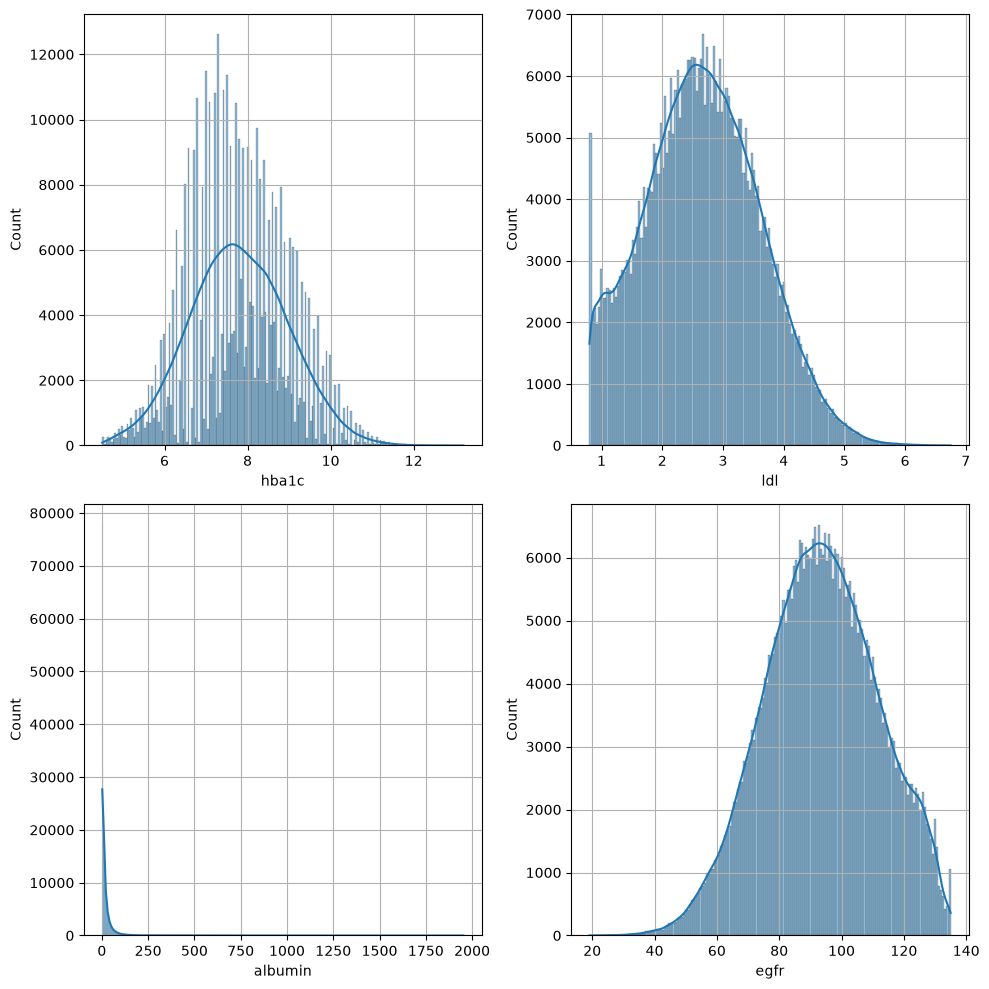

In [45]:
plot_outcome(dict_features = dict_features, df = df_eda)

$2^{nd}$ **Observations.**
- `albumin` feature is strongly right-skewed.
- A `log` transformation should be considered to scale this feature.
##### Task 1e.3: Select features
$1^{st}$ **Note.**

The selected thresholds follow standard rules of thumb:
- Risk Ratio $\geq 1.05 \rightarrow$ minimal relative risk for a clinically non-negligible signal.
- Cramér's V $\geq 0.10 \rightarrow$ small association, useful for not losing weak but real signals.
- AUC $\geq 0.55 / 0.60 \rightarrow$ indicates non-zero discriminant power; a higher threshold is used for continuous features since they tend to be noisier.

In [46]:
dict_selected_features = select_features(dict_dataframes = dict_dataframes)

In [47]:
for key, value in (dict_selected_features.items()):
    print(f"- {key} outcome, selected features {len(value)}, {value}")

- tissue_infection outcome, selected features 8, ['P8_male', 'hh_glycemia', 'acsc_epi', 'acsc_copd', 'acsc_heartf', 'hba1c', 'albumin', 'egfr']
- nephropathy outcome, selected features 9, ['S20_ECI_CHF', 'hh_glycemia', 'acsc_epi', 'acsc_copd', 'acsc_astma', 'acsc_heartf', 'hba1c', 'albumin', 'egfr']


$2^{nd}$ **Which variables are relevant for each of the selected outcomes/complications?**

Applying the threshold selection, only $8$ features out of $29$ were retained for `tissue_infection` outcome, and $9$ for `nephropathy`. Consequently, these are the only features that can be safely described as prominent predictors.

However, we should also consider those features that may enhance predictive power through **interactions** by the primary predictors. Therefore, we manually retained five clinically relevant variables:
- `smoking` $\rightarrow$ a well-known risk factor for vascular complications.
- `S1_CCI_score` $\rightarrow$ a well-known predictor for general clinical complications.
- `ldl` $\rightarrow$ high cholesterol contributes to vascular damage associated with both outcome.
- `S41_ECI_Obesity` $\rightarrow$ obesity is an established risk factor for microvascular complications.
- `S20_ECI_CHF` $\rightarrow$ hyperglycemia damages microcirculation, which is directly linked to nephropathy risk.

Despite not being captured by the threshold selection process, we include them in our final feature set. In addition, `P8_male` and `R5_educ` features were included to satisfy the fairness requirement where necessary (**Task 9**).

In [48]:
dict_final_selected_features = {
    "tissue_infection": dict_selected_features.get("tissue_infection") + ["R5_educ", "S1_CCI_score", "S20_ECI_CHF", "S41_ECI_Obesity", "ldl", "smoking"],
    "nephropathy": dict_selected_features.get("nephropathy") + ["P8_male", "R5_educ", "S1_CCI_score", "ldl", "smoking"],
}

In [49]:
for key, value in dict_final_selected_features.items():
    print(f"- {key} outcome, selected features {len(value)}, {value}")

- tissue_infection outcome, selected features 14, ['P8_male', 'hh_glycemia', 'acsc_epi', 'acsc_copd', 'acsc_heartf', 'hba1c', 'albumin', 'egfr', 'R5_educ', 'S1_CCI_score', 'S20_ECI_CHF', 'S41_ECI_Obesity', 'ldl', 'smoking']
- nephropathy outcome, selected features 14, ['S20_ECI_CHF', 'hh_glycemia', 'acsc_epi', 'acsc_copd', 'acsc_astma', 'acsc_heartf', 'hba1c', 'albumin', 'egfr', 'P8_male', 'R5_educ', 'S1_CCI_score', 'ldl', 'smoking']


### Task 2: Instance coding 
#### Task 2a: From monthly to quarterly data

In [50]:
df_quarter = df_eda.copy()

In [51]:
df_quarter["month_count"] = df_quarter.groupby("pnr").cumcount() + 1
df_quarter["period_id"] = np.ceil(df_quarter["month_count"] / 3).astype(int)

$1^{st}$ **Check.**
- Every patient should have at most 20 `n_periods`.
- Each row combining together the same `pnr` and `period_id` should have a `period_id_count` up to 3.

In [52]:
# Check that all the patients have exactly 20 `n_periods`
max_id = df_quarter.groupby("pnr")["period_id"].max()
assert max_id.eq(20).all(), "Something went wrong"

# Check that each combination between `pnr` and `period_id` has at most three observations
df_quarter["period_id_count"] = df_quarter.groupby(["pnr", "period_id"]).transform("size")
assert (df_quarter["period_id_count"] == 3).all(), "Something went wrong"

In [53]:
df_quarter = df_quarter.drop(["month_count", "period_id_count"], axis = 1)

#### Task 2b: Collapse the data to quarterly level
$1^{st}$ **Explain why we use different aggregation functions.**

Since we are collapsing monthly observations into quarterly data, different types of variables or features require different mathematical representations to avoid losing information. In particular, our **aggregation choices** are:
- `count` $\rightarrow$ `sum`, total number in the quarter.
- `continuous` $\rightarrow$ `mean`, average value over the quarter.
- `binary` $\rightarrow$ `max`, event happened at least once in the quarter.
- `categorical` $\rightarrow$ `max`, the most relevant event occured at least once in the quarter.

In [54]:
MAPPING_AGGREGATION = {
    "date": "first",
    "binary": "max",
    "count": "sum",
    "income": "mean",
    "continuous": "mean",
    "categorical": "max"
}

We have already chosen to study `tissue_infection` and `nephropathy` complications based on our previous analysis. Therefore, we delete from the set of features the other two outcomes `retinopathy` and `cardiovascular`.

In [55]:
dict_features = infer_feature_types(exclude = ["pnr", "year_month", "retinopathy", "cardiovascular", "month", "year"], df = df)

In [56]:
# Take all the already selected features combining it together with the general feature list
list_final_features = list(set(feature for list_features in dict_final_selected_features.values() for feature in list_features)) + TARGET_OUTCOMES

In [57]:
agg = {}
for feature in list_final_features:
    dtype = next((key for key, _ in dict_features.items() if feature in _), None)
    if dtype is None:
        raise KeyError(f"Feature {feature} not found.")

    agg[feature] = MAPPING_AGGREGATION.get(dtype)

In [58]:
df_collapse = df_quarter.groupby(["pnr", "period_id"]).agg(agg).reset_index()

In [59]:
display(df_collapse.head())

,pnr,period_id,hh_glycemia,S1_CCI_score,albumin,smoking,acsc_astma,ldl,acsc_heartf,S41_ECI_Obesity,egfr,S20_ECI_CHF,acsc_epi,hba1c,R5_educ,P8_male,acsc_copd,tissue_infection,nephropathy
0,1,1,0,2,3.954886,2.0,0,2.980000,0,0,103.200,0,0,7.802667,3.0,1,0,0,0
1,1,2,0,2,4.365934,2.0,0,3.030603,0,1,101.400,0,0,7.950421,4.0,1,0,0,0
2,1,3,0,2,3.630873,2.0,0,2.896748,0,0,105.500,0,0,7.710764,4.0,1,0,0,0
3,1,4,0,2,4.227331,2.0,0,2.992433,0,0,103.208,0,0,7.704887,4.0,1,0,0,0
4,1,5,0,2,4.072333,2.0,0,2.890600,0,0,102.800,0,0,7.643587,3.0,1,0,0,0


$2^{nd}$ **Check.**
- All selected final features should be inside the df_collpse dataframe.

In [60]:
for value in dict_final_selected_features.values():
    for column in df_collapse.columns:
        assert column not in value[0] or column not in value[1], f"Feature {column} not present."

#### Task 2c: Find the last period in which each individual is observed and the future periods for each individual

In [61]:
df_window = df_collapse.copy()

In [62]:
# `periods = 12` means 4 quarters ahead
periods = 12

df_window["future_period_id"] = df_window["period_id"] + periods
df_window["max_period"] = df_window.groupby("pnr")["period_id"].transform("max")

In [63]:
display(df_window.head())

,pnr,period_id,hh_glycemia,S1_CCI_score,albumin,smoking,acsc_astma,ldl,acsc_heartf,S41_ECI_Obesity,...,S20_ECI_CHF,acsc_epi,hba1c,R5_educ,P8_male,acsc_copd,tissue_infection,nephropathy,future_period_id,max_period
0,1,1,0,2,3.954886,2.0,0,2.980000,0,0,...,0,0,7.802667,3.0,1,0,0,0,13,20
1,1,2,0,2,4.365934,2.0,0,3.030603,0,1,...,0,0,7.950421,4.0,1,0,0,0,14,20
2,1,3,0,2,3.630873,2.0,0,2.896748,0,0,...,0,0,7.710764,4.0,1,0,0,0,15,20
3,1,4,0,2,4.227331,2.0,0,2.992433,0,0,...,0,0,7.704887,4.0,1,0,0,0,16,20
4,1,5,0,2,4.072333,2.0,0,2.890600,0,0,...,0,0,7.643587,3.0,1,0,0,0,17,20


#### Task 2d: Predict future outcomes

In [64]:
df_future = df_window.copy()

In [65]:
# Bring all target outcomes back to 4 quarters earlier
for outcome in TARGET_OUTCOMES:
    df_future[f"future_{outcome}"] = df_future.groupby("pnr")[outcome].shift(-periods).astype("Int64")

In [66]:
display(df_future.head())

,pnr,period_id,hh_glycemia,S1_CCI_score,albumin,smoking,acsc_astma,ldl,acsc_heartf,S41_ECI_Obesity,...,hba1c,R5_educ,P8_male,acsc_copd,tissue_infection,nephropathy,future_period_id,max_period,future_tissue_infection,future_nephropathy
0,1,1,0,2,3.954886,2.0,0,2.980000,0,0,...,7.802667,3.0,1,0,0,0,13,20,0,0
1,1,2,0,2,4.365934,2.0,0,3.030603,0,1,...,7.950421,4.0,1,0,0,0,14,20,0,0
2,1,3,0,2,3.630873,2.0,0,2.896748,0,0,...,7.710764,4.0,1,0,0,0,15,20,0,0
3,1,4,0,2,4.227331,2.0,0,2.992433,0,0,...,7.704887,4.0,1,0,0,0,16,20,0,0
4,1,5,0,2,4.072333,2.0,0,2.890600,0,0,...,7.643587,3.0,1,0,0,0,17,20,0,0


$1^{st}$ **Explain what buffer period means**.

The **buffer period** is the gap between the end of the observation window and the beginning of the target quarter. It forces the model to predict a non-imminent complication, so it cannot rely on short-term signals, and the prediction comes early enough for an intervention to matter.

$2^{nd}$ **Check.**
- How many NAs?
- How common is the complication: $5\%$ and/or $10\%$?
- Does the logic hold when you inspect one patient?

$2.1^{st}$ **How many NAs?**

In [67]:
_sum = 0
for future_outcome in FUTURE_TARGET_OUTCOMES:
    number_of_null = df_future[[future_outcome]].isna().sum()
    _sum += number_of_null.values[0]

print(f"After shifting the outcomes, the outcomes have {int(_sum / len(FUTURE_TARGET_OUTCOMES))} missing values each.")

After shifting the outcomes, the outcomes have 996456 missing values each.


$2.2^{nd}$ **How common is the complication: $5\%$ and/or $10\%$?**

In [68]:
print(computing_common_percentages(df = df_future))

outcome                  rows    positives    row-level    patient-level
-----------------------  ------  -----------  -----------  ---------------
future_tissue_infection  664304  35720        5.38%        24.43%
future_nephropathy       664304  45197        6.8%         25.32%


$2.2.1^{st}$ **Observations.**
- Percentage `row-level` describes how much the dataset is imbalanced about outcomes.
- These information provide us that we cannot use only `accuracy` metric to evaluate our model. 
- The last percentage, `patient-level`, defines how many patients had the outcome in the last two years. It's useful as additional detail, but it doesn't tell us anything about how much is imbalanced the dataset.
  
$2.3^{rd}$ **Does the logic hold when you inspect one patient?**

In [69]:
df_patient = df_future[df_future["pnr"] == 67]

In [70]:
print(computing_common_percentages(df = df_patient))

outcome                  rows    positives    row-level    patient-level
-----------------------  ------  -----------  -----------  ---------------
future_tissue_infection  8       1            12.5%        100.0%
future_nephropathy       8       2            25.0%        100.0%


#### Task 2e: Rolling measurament over the time

$1^{st}$ **Which choice makes sense for your variables, and why?**

Similar to what was done in the previous **collapsing phase**, the rolling phase is performed according to features' dtypes. Again, we describe our rolling choices as follows:
- `count` $\rightarrow$ `sum`, computing the total number in the $4$ quarters.
- `continuous` $\rightarrow$ `mean`, taking the average over the $4$ quarters.
- `binary` $\rightarrow$ `max`, the event occured at least once in the last $4$ quarters.
- `categorical` $\rightarrow$ `max`, the most relevant event occured at least once in the last $4$ quarters.

In [71]:
MAPPING_ROLLING = {
    "binary": lambda d, f: window(d, f).max(axis = 1),
    "categorical": lambda d, f: window(d, f).max(axis = 1),
    "continuous": lambda d, f: window(d, f).mean(axis = 1),
    "count": lambda d, f: window(d, f).sum(axis = 1, min_count = 1)
}

In [72]:
# Target outcomes kept in the features list since they are prominent predictors 
df_rolling = rolling_dataset(list_features = list_final_features + TARGET_OUTCOMES, exclude = ["P8_male", "R5_educ"], dict_features = dict_features, df = df_future)

In [73]:
list_features_rolled = [df_rolling[column].name for column in df_rolling.columns if "_rolling" in df_rolling[column].name]

#### Task 2f: Drops rows without a full horizon

In [74]:
df_rolling["max_period_tt"] = df_rolling["max_period"] - periods
df_rolling = df_rolling[df_rolling["period_id"] <= df_rolling["max_period_tt"]].copy()

In [75]:
# Keep identifiers and features useful for the fairness evaluation
df_model = df_rolling[["pnr", "period_id", "P8_male", "R5_educ"] + FUTURE_TARGET_OUTCOMES + list_features_rolled].copy()

In [76]:
print(f"Final dataset has {df_model.shape[0]} rows and {df_model.shape[1]} columns.")

Final dataset has 664304 rows and 21 columns.


In [77]:
display(df_model.head())

,pnr,period_id,P8_male,R5_educ,future_tissue_infection,future_nephropathy,hh_glycemia_rolling,S1_CCI_score_rolling,albumin_rolling,smoking_rolling,...,ldl_rolling,acsc_heartf_rolling,S41_ECI_Obesity_rolling,egfr_rolling,S20_ECI_CHF_rolling,acsc_epi_rolling,hba1c_rolling,acsc_copd_rolling,tissue_infection_rolling,nephropathy_rolling
0,1,1,1,3.0,0,0,0.0,2.0,4.044756,2.0,...,2.974946,0.0,1.0,103.32700,0.0,0.0,7.792185,0.0,0.0,0.0
1,1,2,1,4.0,0,0,0.0,2.0,4.074118,2.0,...,2.952596,0.0,1.0,103.22700,0.0,0.0,7.752415,0.0,0.0,0.0
2,1,3,1,4.0,0,0,0.0,2.0,4.111714,2.0,...,2.929867,0.0,0.0,103.32700,0.0,0.0,7.678364,0.0,0.0,0.0
3,1,4,1,4.0,0,0,0.0,2.0,4.138946,2.0,...,2.915680,0.0,0.0,102.53575,0.0,0.0,7.675673,0.0,0.0,0.0
4,1,5,1,3.0,0,0,0.0,2.0,4.116730,2.0,...,2.893236,0.0,1.0,102.23375,0.0,0.0,7.733460,0.0,0.0,0.0


In [78]:
print(f"Number of missing values is {df_model.isna().sum(axis = 1).sum()}.")

Number of missing values is 26344.


In [79]:
x_1 = df.shape[0]
y_1 = df.shape[1]

x_2 = df_model.shape[0]
y_2 = df_model.shape[1]

print(f"After the data preparation phase we have {x_1} --> {x_2} rows and {y_1} --> {y_2} columns.")

After the data preparation phase we have 4982280 --> 664304 rows and 40 --> 21 columns.


### Task 3: Feature engineering
$1^{st}$ **Consider whether any variables should be transformed.**

This section is mainly needed for `LogisticRegression`. The model assumes that the relation between a feature and an outcome is **linear**: if the real relation is not, the modell will provide **poor predictions**.

A simple fix is to split continuous features into groups - this is called **binning**. For `hba1c_rolling` and `egfr_rolling` we split at **clinical threshold**. For `albumin_rolling` we use a **log transform** instead, because the feature is highly skewed on the right.

Other models like `RandomForest` and `XGBoost` don't have this issue: they split  the feature space by construction and can capture non-linear relations directly. We examine the continuous features separately for each outcome. We start from `future_tissue_infection` (blue plots) and then we move on to `future_nephropathy` (orange plots).

In [80]:
list_continuous_features = [column for column in df_model.columns if column.replace("_rolling", "") in dict_features.get("continuous")]

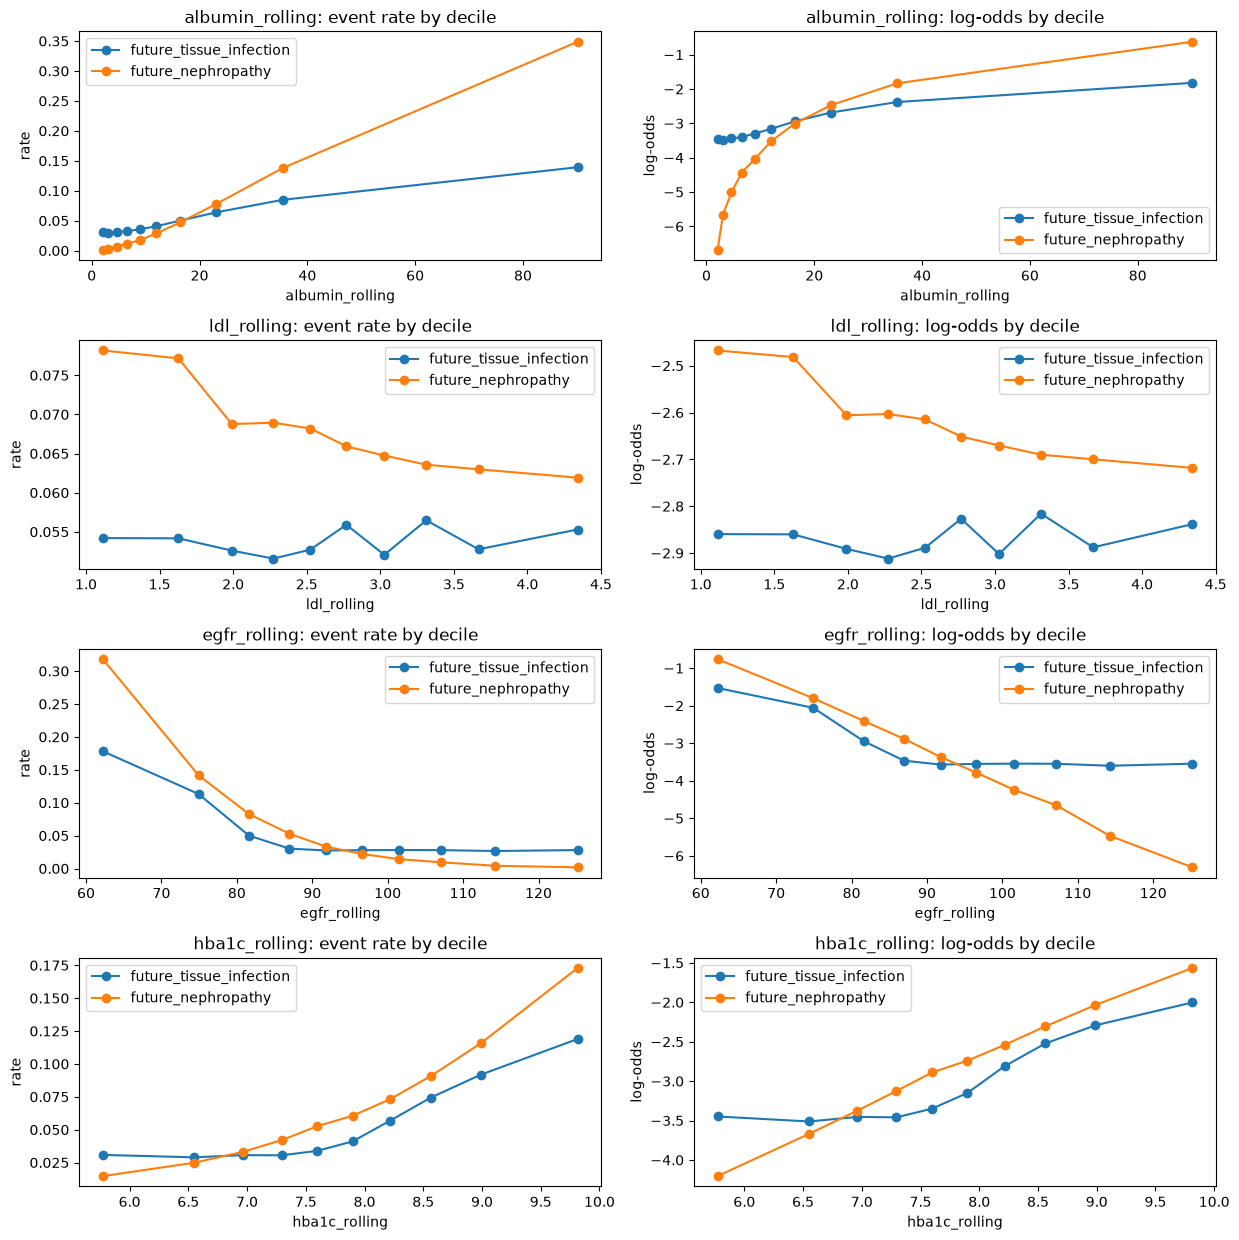

In [81]:
if len(list_continuous_features) > 0:
    examine_continuous_features(list_features = list_continuous_features, df = df_model)

$2.1^{st}$ **Observations - `future_tissue_infection`.**
1. `albumin_rolling` $\rightarrow$ heavily skewed. The relation is non-linear $\rightarrow$ **Log transform** is required, it linearizes the existing relation and compresses the tail.
2. `ldl_rolling` $\rightarrow$ the curve is essentially flat, suggesting weak or no association with the outcome $\rightarrow$ No action is required, keep it continuous.
3. `egfr_rolling` $\rightarrow$ flat above $\sim 90$ and steep drop below $\sim 60$. The relation is clearly non-linear $\rightarrow$ Binning at clinical thresholds (`<30`, `30-59`, `60-89`, `>=90`).
4. `hba1c_rolling` $\rightarrow$ flat below $\sim 7.5$ decile and then it grows rapidly. The relation is non-linear $\rightarrow$ Binning at clinical thresholds (`<7`, `7-8`, `>=8`).

$2.2^{nd}$ **Observations - `future_nephropathy`.**
1. `albumin_rolling` $\rightarrow$ monotone but concave. The feature is heavily right-skewed. $\rightarrow$ `Log transform` is required. 
2. `ldl_rolling` $\rightarrow$ flat curve, suggesting weak or no association with the outcome $\rightarrow$ Keep it continuous.
3. `egfr_rolling` $\rightarrow$ even more pronounced than before. The relation is non-linear $\rightarrow$ binning at clinical thresholds (`<30`, `30-59`, `60-89`, `>=90`).
4. `hba1c_rolling` $\rightarrow$ grows across deciles, with a sharp acceleration above $\sim 8$. The relation is non-linear $\rightarrow$ binning at clinical thresholds (`<7`, `7-8`, `>=8`).

All the continuous features show a non-linear relationship with the selected outcomes. At the end of the examination, the final decision is to split `egfr_rolling` and `hba1c_rolling` features into groups and apply a **log** transformation to the right-skewed `albumin_rolling` feature.

In [82]:
df_model = split_continuous_in_groups(df = df_model)

In [83]:
display(df_model.head())

,pnr,period_id,P8_male,R5_educ,future_tissue_infection,future_nephropathy,hh_glycemia_rolling,S1_CCI_score_rolling,albumin_rolling,smoking_rolling,...,egfr_rolling,S20_ECI_CHF_rolling,acsc_epi_rolling,hba1c_rolling,acsc_copd_rolling,tissue_infection_rolling,nephropathy_rolling,egfr_binned,hba1c_binned,albumin_log
0,1,1,1,3.0,0,0,0.0,2.0,4.044756,2.0,...,103.32700,0.0,0.0,7.792185,0.0,0.0,0.0,>=90,7-8,1.618349
1,1,2,1,4.0,0,0,0.0,2.0,4.074118,2.0,...,103.22700,0.0,0.0,7.752415,0.0,0.0,0.0,>=90,7-8,1.624153
2,1,3,1,4.0,0,0,0.0,2.0,4.111714,2.0,...,103.32700,0.0,0.0,7.678364,0.0,0.0,0.0,>=90,7-8,1.631535
3,1,4,1,4.0,0,0,0.0,2.0,4.138946,2.0,...,102.53575,0.0,0.0,7.675673,0.0,0.0,0.0,>=90,7-8,1.636848
4,1,5,1,3.0,0,0,0.0,2.0,4.116730,2.0,...,102.23375,0.0,0.0,7.733460,0.0,0.0,0.0,>=90,7-8,1.632516


### Task 4: One-hot encoding of categorical variables
$1^{st}$ **What does and is one-hot encoding?**

**One-hot encoding** is a preprocessing technique frequently used to handle categorical data. This technique separates each category of a variable into distinct features: if a categorical variable has $N$ different categories, one-hot encoding will provide $N$ different binary features representing those categories.

$2^{nd}$ **Why is it relevant for machine learning?**

Since all machine learning models can only deal with **numerical values**, using the one-hot encoding technique we can convert categorical data into numbers without losing any information.

In [84]:
list_categorical_features = detect_categorical_features(df = df_model)

In [85]:
if len(list_categorical_features) > 0:
    df_final = transform_categorical_in_binary(list_features = list_categorical_features, df = df_model)

In [86]:
display(df_final.head())

,pnr,period_id,P8_male,R5_educ,future_tissue_infection,future_nephropathy,hh_glycemia_rolling,S1_CCI_score_rolling,albumin_rolling,smoking_rolling,...,egfr_binned,hba1c_binned,albumin_log,<30,30-59,60-89,>=90,<7,7-8,>=8
0,1,1,1,3.0,0,0,0.0,2.0,4.044756,2.0,...,>=90,7-8,1.618349,0,0,0,1,0,1,0
1,1,2,1,4.0,0,0,0.0,2.0,4.074118,2.0,...,>=90,7-8,1.624153,0,0,0,1,0,1,0
2,1,3,1,4.0,0,0,0.0,2.0,4.111714,2.0,...,>=90,7-8,1.631535,0,0,0,1,0,1,0
3,1,4,1,4.0,0,0,0.0,2.0,4.138946,2.0,...,>=90,7-8,1.636848,0,0,0,1,0,1,0
4,1,5,1,3.0,0,0,0.0,2.0,4.116730,2.0,...,>=90,7-8,1.632516,0,0,0,1,0,1,0


### Task 5: Split data to machine learning
$1^{st}$ **Explain why you split as you do.**

Splitting the dataset by rows would cause **data leakage**: the model would recognize the patient rather than learning patterns. Therefore, we need to split the data according to patients' ids, so that training set and test set have different observations. 

In [87]:
ids = df_final["pnr"].unique()
train_ids = pd.Series(ids).sample(frac = 0.7, random_state = RANDOM_STATE).values

train_df = df_final[df_final["pnr"].isin(train_ids)]
test_df = df_final[~df_final["pnr"].isin(train_ids)]

In [88]:
assert ((train_df.shape[0] + test_df.shape[0]) == df_final.shape[0]), "Number of rows does not coincide."

In [89]:
assert (train_df["pnr"].isin(test_df["pnr"]).sum() == 0), "People ids (`pnr`) are shared between train set and test set."

## Part 2: Machine Learning
### Task 6: Choice of ML models
$1^{st}$ **What is class imbalance, and how does it affect the model?** 

**Class imbalance** occurs when the classes of a classification dataset are not equally represented. More specifically, a dataset has class imbalance when its **class distribution** is uneven, with some labels appearing far more often than others. The main problem of class imbalance is that machine learning models become biased towards the majority class, often performing poorly on the minority class.

$2^{nd}$ **Which metric is most important: sensitivity, specificity or AUC?**

Based on the type of goal that we are pursuing, we can justify that the `sensitivity` metric is the most important: detecting all possible patients who may experience complications in the future.
However, if cost containment is also a concern, we should also consider the `specificity` metric: avoiding classifying all those patients as problematic, even if they are not really. Finally, the `AUC` metric provides an overall measure of the model's ability to distinguish between positive and negative classes, summarizing the sensitivity–specificity trade-off across all possible thresholds.

### Task 7: Carry out the ML analysis

In [90]:
FEATURES = {
    "future_tissue_infection": {
        "lr": ["P8_male", "R5_educ", "acsc_epi_rolling", "hh_glycemia_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "S41_ECI_Obesity_rolling", "tissue_infection_rolling", "<30", "30-59", "60-89", ">=90", "<7", "7-8", ">=8", "albumin_log"],
        "rf": ["P8_male", "R5_educ", "acsc_epi_rolling", "hh_glycemia_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "S41_ECI_Obesity_rolling", "tissue_infection_rolling", "hba1c_rolling", "egfr_rolling", "albumin_rolling"],
        "xgb": ["P8_male", "R5_educ", "acsc_epi_rolling", "hh_glycemia_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "S41_ECI_Obesity_rolling", "tissue_infection_rolling", "hba1c_rolling", "egfr_rolling", "albumin_rolling"],
    },
    "future_nephropathy": {
        "lr": ["P8_male", "R5_educ", "hh_glycemia_rolling", "acsc_epi_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "acsc_astma_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "nephropathy_rolling", "<30", "30-59", "60-89", ">=90", "<7", "7-8", ">=8", "albumin_log"],
        "rf": ["P8_male", "R5_educ", "hh_glycemia_rolling", "acsc_epi_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "acsc_astma_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "nephropathy_rolling", "hba1c_rolling", "egfr_rolling", "albumin_rolling"],
        "xgb": ["P8_male", "R5_educ", "hh_glycemia_rolling", "acsc_epi_rolling", "acsc_copd_rolling", "acsc_heartf_rolling", "ldl_rolling", "smoking_rolling", "acsc_astma_rolling", "S1_CCI_score_rolling", "S20_ECI_CHF_rolling", "nephropathy_rolling", "hba1c_rolling", "egfr_rolling", "albumin_rolling"],
    }
}

#### Task 7a: Define datasets, cross-validations and pipelines over a sample of the training set
$1^{st}$ **Note.**

Due to computational constraints, the **cross-validation** phase is performed taking into account a sample of the original training set. After that, we take the best models, based on the best hyperparameters, and we train them on the entire training set.

In [91]:
train_df_sample = get_sample(sample_ratio = 0.5, df = train_df)

In [92]:
SAMPLE_DATASETS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    SAMPLE_DATASETS[outcome] = {}
    for model in MODELS:
        X_train, y_train, g_train = get_xy(model = model, outcome = outcome, df = train_df_sample)

        SAMPLE_DATASETS[outcome][model] = {
            "X_train": X_train,
            "y_train": y_train,
            "g_train": g_train,
        }

In [93]:
FOLDS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    y = train_df_sample[outcome]
    groups = train_df_sample["pnr"]

    cv = StratifiedGroupKFold(n_splits = 5, shuffle = True, random_state = RANDOM_STATE)

    FOLDS[outcome] = list(cv.split(X = train_df_sample, y = y, groups = groups))

In [94]:
PIPELINES = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    PIPELINES[outcome] = {}
    for model in MODELS:
        if model == "lr":
            PIPELINES[outcome][model] = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy = "median")), 
                    ("scaler", StandardScaler()), 
                    ("model", LogisticRegression(random_state = RANDOM_STATE))
                ]
            )
        elif model == "rf":
            PIPELINES[outcome][model] = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy = "median")), 
                    ("model", RandomForestClassifier(n_jobs = 1, random_state = RANDOM_STATE))
                ]
            )
        elif model == "xgb":
            PIPELINES[outcome][model] = Pipeline(
                [
                    ("model", XGBClassifier(tree_method = "hist", n_jobs = 1, random_state = RANDOM_STATE ))
                ]
            )
        else:
            raise KeyError(f"Key {model} not found")

#### Task 7b: Defining a hyperparameter grid

In [95]:
HYPERPARAMETERS_GRID = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    HYPERPARAMETERS_GRID[outcome] = {}
    for model in MODELS:
        if model == "lr":
            HYPERPARAMETERS_GRID[outcome][model] = {
                "model__class_weight": [{0: 1, 1: w} for w in [1, 5, 10, 20, 50]],
                "model__C": [0.001, 0.01, 0.1, 1.0, 10.0],
                "model__l1_ratio": [0, 0.25, 0.5, 0.75, 1]
            }
        elif model == "rf":
            HYPERPARAMETERS_GRID[outcome][model] = {
                "model__n_estimators": [300, 500],
                "model__max_depth": [8, 10, 12, 14, 16, 20],
                "model__min_samples_leaf": [20, 50, 100, 200, 400],
                "model__max_features": ["sqrt", 0.2, 0.3, 0.5],
                "model__class_weight": [{0: 1, 1: w} for w in [1, 5, 10, 20, 50]],
                "model__max_samples": [0.1, 0.2, 0.3, 0.5],
            }
        elif model == "xgb":
            HYPERPARAMETERS_GRID[outcome][model] = {
                "model__n_estimators": [200, 400, 600],
                "model__max_depth": [3, 4, 5, 6, 8],
                "model__learning_rate": [0.08, 0.1, 0.15],
                "model__min_child_weight": [1, 5, 10, 20],
                "model__subsample": [0.6, 0.7, 0.9, 1.0],
                "model__colsample_bytree": [0.5, 0.8, 1.0],
                "model__scale_pos_weight": [1, 5, 10, 20, 50]
            }
        else:
            raise KeyError(f"Key {model} not found")

In [96]:
GRIDS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    GRIDS[outcome] = {}
    for model in MODELS:
        if model == "lr":
            GRIDS[outcome][model] = GridSearchCV(
                estimator = PIPELINES[outcome][model],
                param_grid = HYPERPARAMETERS_GRID[outcome][model],
                scoring = "recall",
                cv = FOLDS[outcome]
            )
        elif model == "rf":
            GRIDS[outcome][model] = RandomizedSearchCV(
                estimator = PIPELINES[outcome][model],
                param_distributions = HYPERPARAMETERS_GRID[outcome][model],
                n_iter = 20,
                scoring = "recall",
                n_jobs = -1,
                cv = FOLDS[outcome],
                random_state = RANDOM_STATE
            )
        elif model == "xgb":
            GRIDS[outcome][model] = RandomizedSearchCV(
                estimator = PIPELINES[outcome][model],
                param_distributions = HYPERPARAMETERS_GRID[outcome][model],
                n_iter = 20,
                scoring = "recall",
                n_jobs = -1,
                cv = FOLDS[outcome],
                random_state = RANDOM_STATE
            )
        else:
            raise KeyError(f"Key {model} not found")

$1^{st}$ **Note.**

Hyperparameter tuning consists in searching for the best combination of hyperparameter values to increase the models' performance. `GridSearchCV` and `RandomizedSearchCV` are tools that help us to find out those values inside the **hyperparameter space**. 

The main difference between these two techniques is: the first one picks every possible combination from a provided hyperparameter grid, while, on the other hand, the second one randomly samples from a distribution of hyperparameter values. Therefore, with `RandomizedSearchCV` we no longer have an exhaustive search like `GridSearchCV`, but we can speed up the training phase of our models.

In [97]:
results = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    results[outcome] = {}
    for model in MODELS:
        grid_search = GRIDS[outcome][model]
        grid_search.fit(X = SAMPLE_DATASETS[outcome][model]["X_train"], y = SAMPLE_DATASETS[outcome][model]["y_train"])

        results[outcome][model] = {
            "best_params": grid_search.best_params_,
            "best_cv_score": grid_search.best_score_
        }

#### Task 7d: Training on the best hyperparameters
$1^{st}$ **Note.**

As we mentioned before, the cross-validation phase is performed only on a sample of the training set. In the snippet of code below, we define datasets across the entire training and test dataframes.

In [98]:
DATASETS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    DATASETS[outcome] = {}
    for model in MODELS:
        X_train, y_train, g_train = get_xy(model = model, outcome = outcome, df = train_df)
        X_test, y_test, g_test = get_xy(model = model, outcome = outcome, df = test_df)

        DATASETS[outcome][model] = {
            "X_train": X_train,
            "y_train": y_train,
            "g_train": g_train,
            "X_test": X_test,
            "y_test": y_test,
            "g_test": g_test,
        }

In [99]:
FINAL_MODELS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    FINAL_MODELS[outcome] = {}
    for model in MODELS:
        estimator = clone(PIPELINES[outcome][model]).set_params(**results[outcome][model]["best_params"])
        estimator.fit(X = DATASETS[outcome][model]["X_train"], y = DATASETS[outcome][model]["y_train"])
        
        FINAL_MODELS[outcome][model] = estimator

#### Task 7e: Testing on unseen data
$1^{st}$ **Note.**

The `cutoff` is defined such that each model identifies at least $80\%$ of patients who may have a complication.

In [100]:
CUTOFFS = {}
for outcome in FUTURE_TARGET_OUTCOMES:
    CUTOFFS[outcome] = {}
    for model in MODELS:
        dataset = DATASETS[outcome][model]
        
        CUTOFFS[outcome][model] = find_cutoff(
            target_sensitivity = 0.80,
            X = dataset["X_train"], 
            y = dataset["y_train"], 
            groups = dataset["g_train"], 
            estimator = FINAL_MODELS[outcome][model]
        )

In [101]:
cms, probs, y_preds = {}, {}, {}
for outcome in FUTURE_TARGET_OUTCOMES:
    cms[outcome] = {}
    probs[outcome] = {}
    y_preds[outcome] = {}
    for model in MODELS:
        cutoff = CUTOFFS[outcome][model]
        estimator = FINAL_MODELS[outcome][model]

        X_test = DATASETS[outcome][model]["X_test"]
        y_true = DATASETS[outcome][model]["y_test"]
        
        # Take only prediction with label `1` probabilities
        prob = estimator.predict_proba(X_test)[:, 1]
        probs[outcome][model] = prob

        y_pred = (prob >= CUTOFFS[outcome][model]).astype(int)
        y_preds[outcome][model] = y_pred

        cm = confusion_matrix(y_true = y_true, y_pred = y_pred)
        cms[outcome][model] = cm

### Task 8: Confusion matrix and model performance

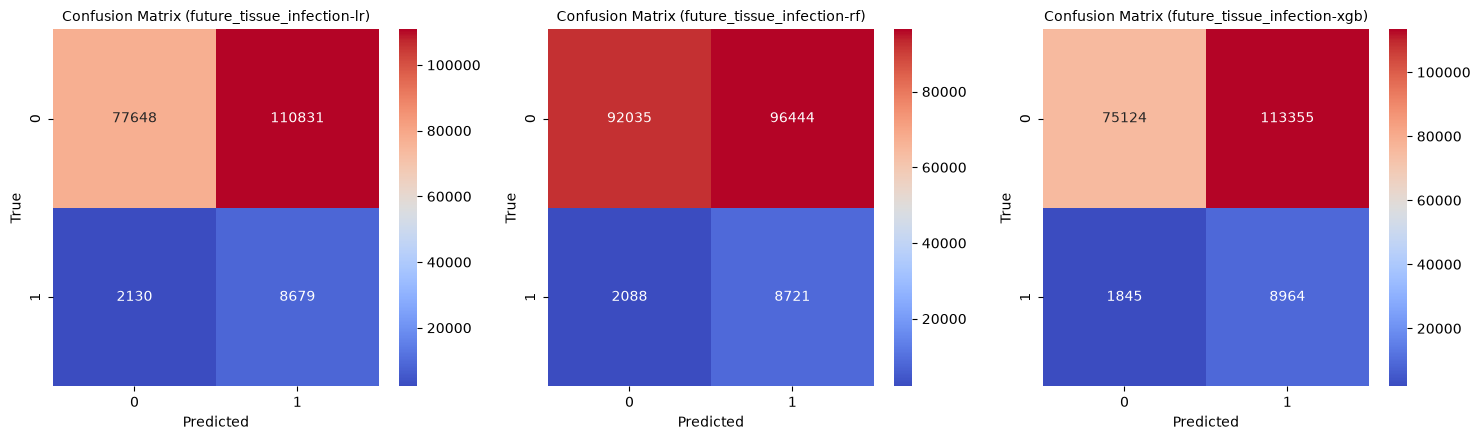

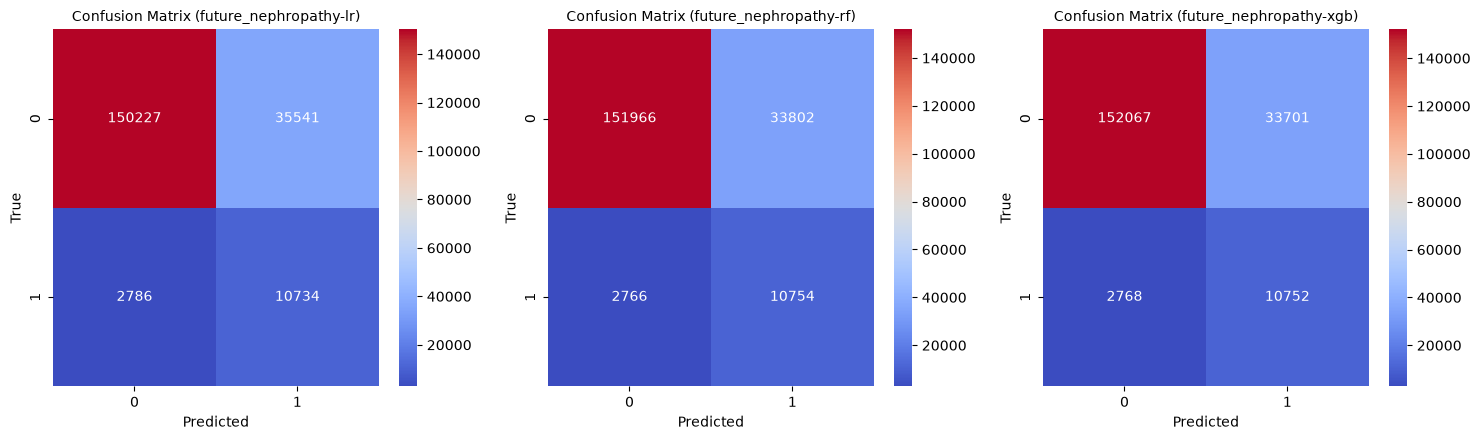

In [102]:
for outcome in FUTURE_TARGET_OUTCOMES:
    plot_confusion_matrices(cms = cms[outcome])

In [103]:
metrics = compute_models_performance(cms = cms, probs = probs)

In [104]:
dict_df_metrics = {outcome: pd.DataFrame(metrics[outcome]) for outcome in metrics.keys()}

In [105]:
display(HTML(provide_html(dict = dict_df_metrics)))

,lr,rf,xgb
sensitivity,0.8029,0.8068,0.8293
specificity,0.4120,0.4883,0.3986
precision,0.0726,0.0829,0.0733
npv,0.9733,0.9778,0.9760
f1_score,0.1332,0.1504,0.1347
roc_auc,0.7338,0.7716,0.7528
pr_auc,0.2481,0.3104,0.3008
,lr,rf,xgb
sensitivity,0.7939,0.7954,0.7953
specificity,0.8087,0.8180,0.8186


In [106]:
dict_best_cv_scores = dict()
for model in MODELS:
    dict_best_cv_scores[model] = [round(value[model]["best_cv_score"], 4) for value in results.values()]

In [107]:
dict_auc_scores = dict()
for model in MODELS:
    dict_auc_scores[model] = [round(value[model]["roc_auc"], 4) for value in metrics.values()]

In [108]:
df_best_cv_scores = pd.concat([pd.DataFrame().from_dict(dict_best_cv_scores)]).reset_index(drop = True)
df_auc_scores = pd.concat([pd.DataFrame().from_dict(dict_auc_scores)]).reset_index(drop = True)

df_best_cv_scores.index = [outcome for outcome in FUTURE_TARGET_OUTCOMES] 
df_auc_scores.index = [outcome for outcome in FUTURE_TARGET_OUTCOMES]

display(HTML(provide_html(dict = {"cv_scores": df_best_cv_scores, "auc_scores": df_auc_scores})))

,lr,rf,xgb
future_tissue_infection,0.9370,0.9597,0.6629
future_nephropathy,0.9452,0.9523,0.8647
,lr,rf,xgb
future_tissue_infection,0.7338,0.7716,0.7528
future_nephropathy,0.8838,0.8882,0.8887


$1^{st}$ **Results.**

The `cutoff` was defined to achieve a sentitivity of $80\%$ on the training set. That's why `sensitivity` is almost equal across machine learning models: the real comparison is about how many **false alarms** each model needs in order to reach that `recall` value.

For **future_nephropathy**, all three models perform almost equally (sensitivity around $0.79$, specificity around $0.80$-$0.81$, AUC around $0.88$). Simply put, $1$ flagged patient out of $4$ develops nephropathy complications. The difference between `LogisticRegression`, `RandomForestClassifier` and `XGBClassifier` is very small, suggesting that the predictive power comes from the data rather than from the type of model chosen. For **future_tissue_infection**, the signal is **weaker**. To capture the target sensitivity, the model must flag more than half of the patients, producing many **false alarms** and simultaneously reducing its `precision` to very small values. One possible explanation could be that nephropathy is a progressive disease, while tissue infection is more episodic and more difficult to predict.

`RandomForestClassifier` is the most convincing estimator for tissue infection: it has the highest `AUC` ($0.77$) and `PR-AUC` ($0.31$), and fewer alarms at the same sensitivity. `XGBoost` has the highest sensitivity ($0.82$), but it has the lowest specificity and precision.

### Task 9: Fairness analysis
$1^{st}$ **Note.**

The fairness analysis is performed on the best model for each selected outcome. Please note that the best models were chosen based on the `AUC` metric.

In [109]:
best_models = get_best_models(metric = "roc_auc", metrics = dict_df_metrics, dict_models = FINAL_MODELS)

In [110]:
fairness_dataframes = get_fairness_dataframes(models = best_models)

In [111]:
METRICS = {
    "true_positive_rate": true_positive_rate,
    "false_positive_rate": false_positive_rate,
    "statistical_parity": selection_rate
}

In [112]:
fairness_results = {}
for outcome, value in fairness_dataframes.items():
    fairness_results[outcome] = {}
    for model, _df in value.items():
        y_true = _df["y_true"]
        y_pred = _df["y_pred"]

        gender = _df["P8_male"]
        education = _df["R5_educ"]

        mf_gender = MetricFrame(
            metrics = METRICS,
            y_true = y_true,
            y_pred = y_pred,
            sensitive_features = gender,
            random_state = RANDOM_STATE
        )

        mf_education = MetricFrame(
            metrics = METRICS,
            y_true = y_true,
            y_pred = y_pred,
            sensitive_features = education,
            random_state = RANDOM_STATE
        )

        tables = []
        for mf in (mf_gender, mf_education):
            table = mf.by_group.copy()
            table.loc["ratio"] = mf.ratio(method = "between_groups")
            table.index.name = mf.by_group.index.name
            tables.append(table)

        fairness_results[outcome][model] = [mf_gender.by_group, mf_education.by_group] + tables

In [113]:
_ = {}
for outcome, value in fairness_results.items():
    for model, mfs in value.items():
        for mf in mfs:
            _[f"{outcome} - {mf.index.name} - {model}"] = mf

display(HTML(provide_html(dict = _)))

,true_positive_rate,false_positive_rate,statistical_parity
P8_male,,,
0,0.792530,0.490075,0.505722
1,0.818565,0.531172,0.547404
ratio,0.968195,0.922630,0.923855
,true_positive_rate,false_positive_rate,statistical_parity
R5_educ,,,
2.0,0.809249,0.507756,0.526278
3.0,0.816568,0.530960,0.547019
4.0,0.803990,0.506532,0.522465
ratio,0.984597,0.953994,0.955114


$2^{nd}$ **Does the model work equally well for everyone?**
- `future_nephropathy` $\rightarrow$ the groups are almost identical, both in gender and in education. The `TPR` is between $0.79$ and $0.80$, the `FPR` is approximately $0.18$, and the selection rate is around $0.22$. The model `XGBClassifier` captures everyone equally.
- `future_tissue_infection` $\rightarrow$ the education groups are pratically equal (`TPR` around $0.80$-$0.81$, `FPR` around $0.51$-$0.53$). Regarding gender, there is a small difference: female patients are captured slightly less often than male patients. 

$3^{rd}$ **Note.**

The ratios - in particular the `TPR` ones - sit between $0.92$ and $0.99$, which keeps them within the $0.80$-$1.25$ range. 